--- ตารางสัดส่วนยอดขาย (%) แยกตาม 3 ภูมิภาคหลัก ---
                 NA (%)  EU (%)  JP (%)
Publisher                              
Electronic Arts   59.41   39.22    1.37
Nintendo          44.41   29.92   25.67
Ubisoft           59.74   38.73    1.53

--- ค่าเฉลี่ยยอดขายรวมต่อเกม (ล้านชุด) ---
                 Mean Sales
Publisher                  
Electronic Arts        0.81
Nintendo               2.30
Ubisoft                0.53


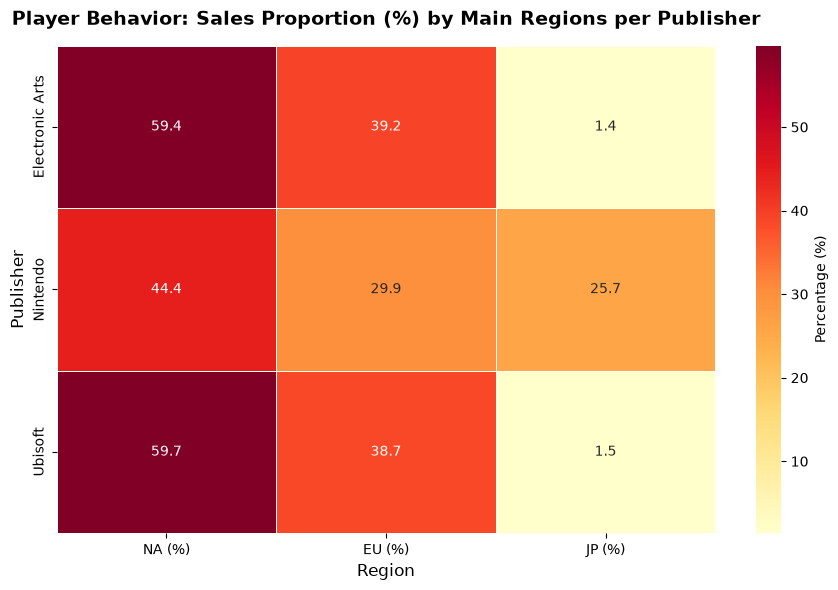

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. เรียกอ่านข้อมูลจากไฟล์ (เปลี่ยนชื่อไฟล์ตามที่คุณตั้งไว้ได้เลย)
file_path = "../data/processed/Game_data_clean.xlsx"
df = pd.read_excel(file_path)

# 2. เลือกเฉพาะ 3 ภูมิภาคหลัก (ไม่รวม Other_Sales) แยกตามค่ายเกม (Publisher)
main_regions = ["NA_Sales", "EU_Sales", "JP_Sales"]
df_grouped = df.groupby("Publisher")[main_regions].sum()

# 3. แปลงยอดขายให้เป็น "สัดส่วนเปอร์เซ็นต์ (%)" ของทั้ง 3 ภูมิภาคนี้
df_percentage = df_grouped.div(df_grouped.sum(axis=1), axis=0) * 100
df_percentage.columns = ["NA (%)", "EU (%)", "JP (%)"]

# 4. คำนวณค่าเฉลี่ย (Mean) ยอดขายรวมต่อเกม (Global_Sales) ของแต่ละค่าย
df_mean = (
    df.groupby("Publisher")["Global_Sales"].mean().to_frame(name="Mean Sales")
)

# 5. แสดงผลลัพธ์เป็นตารางบนหน้าจอคอมพิวเตอร์
print("--- ตารางสัดส่วนยอดขาย (%) แยกตาม 3 ภูมิภาคหลัก ---")
print(df_percentage.round(2))
print("\n--- ค่าเฉลี่ยยอดขายรวมต่อเกม (ล้านชุด) ---")
print(df_mean.round(2))

# 6. สร้างแผนภาพความร้อน (Heatmap)
plt.figure(figsize=(9, 6))

# ใช้ seaborn วาด Heatmap เฉพาะ 3 ภูมิภาคหลัก
sns.heatmap(
    df_percentage,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Percentage (%)"},
)

# ตั้งค่าหัวข้อกราฟและป้ายชื่อแกน
plt.title(
    "Player Behavior: Sales Proportion (%) by Main Regions per Publisher",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.ylabel("Publisher", fontsize=12)
plt.xlabel("Region", fontsize=12)

# ปรับการจัดวางและแสดงผลกราฟ
plt.tight_layout()
plt.show()

R-squared (R2): 0.9987
RMSE: 0.1027


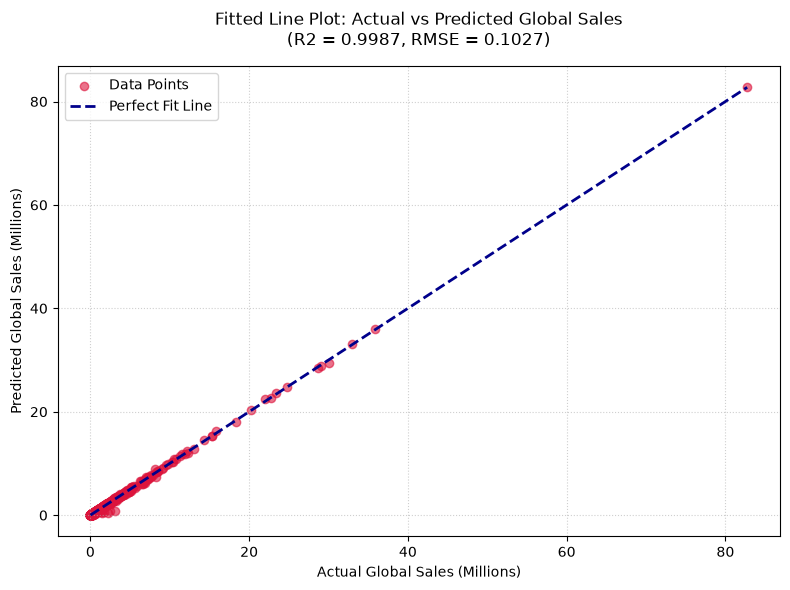

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. โหลดข้อมูลจากไฟล์ (เปลี่ยนชื่อไฟล์ให้ตรงกับของคุณ)
file_path = "../data/processed/Game_data_clean.xlsx"
df = pd.read_excel(file_path)
# แปลงข้อมูลในคอลัมน์ยอดขายให้เป็นตัวเลขเชิงปริมาณ
sales_cols = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Global_Sales']
for col in sales_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=sales_cols)

# 2. กำหนดตัวแปรต้น (X) และตัวแปรตาม (y)
X = df[['NA_Sales', 'EU_Sales', 'JP_Sales']]
y = df['Global_Sales']

# 3. สร้างและฝึกสอนแบบจำลอง Linear Regression
model = LinearRegression()
model.fit(X, y)

# 4. พยากรณ์ผลลัพธ์
y_pred = model.predict(X)

# 5. คำนวณค่าความแม่นยำ $R^2$ และ RMSE
r2 = r2_score(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))

print(f"R-squared (R2): {r2:.4f}")
print(f"RMSE: {rmse:.4f}")

# 6. พลอตกราฟ Fitted Line Plot (Actual vs Predicted)
plt.figure(figsize=(8, 6))
# พลอตจุดข้อมูลจริงเปรียบเทียบกับค่าพยากรณ์
plt.scatter(y, y_pred, color='crimson', alpha=0.6, label='Data Points')

# สร้างเส้น Fitted Line (เส้นตรง 45 องศาที่แสดงถึงการพยากรณ์ที่สมบูรณ์แบบ)
ideal_line = np.linspace(y.min(), y.max(), 100)
plt.plot(ideal_line, ideal_line, color='darkblue', linestyle='--', linewidth=2, label='Perfect Fit Line')

# ตั้งค่ารายละเอียดกราฟเป็นภาษาอังกฤษเพื่อป้องกันฟอนต์ระบบเจ๊ง
plt.title(f'Fitted Line Plot: Actual vs Predicted Global Sales\n(R2 = {r2:.4f}, RMSE = {rmse:.4f})', fontsize=12, pad=15)
plt.xlabel('Actual Global Sales (Millions)', fontsize=10)
plt.ylabel('Predicted Global Sales (Millions)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


In [3]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

# 1. โหลดข้อมูลจากไฟล์ CSV
file_path = "../data/processed/Game_data_clean.xlsx"
df = pd.read_excel(file_path)
# 2. แปลงข้อมูลในคอลัมน์ยอดขายให้เป็นตัวเลขเชิงปริมาณ และตัดแถวที่มีค่าว่างออก
sales_cols = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Global_Sales']
for col in sales_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=sales_cols)

# 3. กำหนดตัวแปรต้น (X: ยอดขายภูมิภาคหลัก) และตัวแปรตาม (y: ยอดขายทั่วโลก)
X = df[['NA_Sales', 'EU_Sales', 'JP_Sales']]
y = df['Global_Sales']

# 4. สร้างและฝึกสอนแบบจำลอง Linear Regression
model = LinearRegression()
model.fit(X, y)

# 5. แสดงผลค่าจุดตัดแกน Y และค่าสัมประสิทธิ์ของแต่ละภูมิภาค (ตอบคำถามข้อ 3)
print("==========================================================")
print("📊 ผลการวิเคราะห์ค่าสัมประสิทธิ์ (Linear Regression Coefficients)")
print("==========================================================")
print(f"ค่าจุดตัดแกน Y (model.intercept_)  : {model.intercept_:.4f}")
print("----------------------------------------------------------")
print("ค่าสัมประสิทธิ์แยกตามภูมิภาค (model.coef_):")

# จัดเรียงเพื่อเปรียบเทียบน้ำหนักอิทธิพล
features = ['NA_Sales (อเมริกาเหนือ)', 'EU_Sales (ยุโรป)', 'JP_Sales (ญี่ปุ่น)']
coef_dict = dict(zip(features, model.coef_))

# พิมพ์ค่าสัมประสิทธิ์เรียงตามลำดับความสำคัญจากมากไปน้อย
for feature, coef in sorted(coef_dict.items(), key=lambda item: item[1], reverse=True):
    print(f"- {feature:<25} : {coef:.4f}")

print("==========================================================")
print("💡 สรุป: ภูมิภาคที่ส่งผลต่อการเติบโตของยอดขายรวมทั่วโลกมากที่สุด")
print(f"คือ {max(coef_dict, key=coef_dict.get)} ด้วยค่าสัมประสิทธิ์ {max(coef_dict.values()):.4f}")
print("==========================================================")


📊 ผลการวิเคราะห์ค่าสัมประสิทธิ์ (Linear Regression Coefficients)
ค่าจุดตัดแกน Y (model.intercept_)  : 0.0081
----------------------------------------------------------
ค่าสัมประสิทธิ์แยกตามภูมิภาค (model.coef_):
- EU_Sales (ยุโรป)          : 1.2182
- NA_Sales (อเมริกาเหนือ)   : 1.0554
- JP_Sales (ญี่ปุ่น)        : 0.9575
💡 สรุป: ภูมิภาคที่ส่งผลต่อการเติบโตของยอดขายรวมทั่วโลกมากที่สุด
คือ EU_Sales (ยุโรป) ด้วยค่าสัมประสิทธิ์ 1.2182


In [5]:
import pandas, numpy, seaborn, matplotlib, sklearn
print(pandas.__version__, numpy.__version__, seaborn.__version__, matplotlib.__version__, sklearn.__version__)

3.0.6 2.5.3 0.13.2 3.11.2 1.9.1
